# Milestone 2 · Generation: guidance and step count on dev_500

**Owner:** Tanmayi · **Protocol:** `m2-v1` (shared `m2_protocol.py`, diffusers 0.42.1)

This notebook paints every image for my two Milestone 2 sweeps with the group's shared generation code, so the images are paired caption for caption, and noise for noise, with everyone else's.

| Sweep | Setting changed from the anchor | Captions | Seeds | Images |
|---|---|---|---|---|
| Guidance | classifier-free guidance 3, 5, 7.5, 10, 12 | all 500 of `dev_500` | seed_id 0 | 2,500 |
| Diversity pairs | the same five guidance values | first 100 of `dev_500` | seed_id 1 | 500 |
| Step count | 10, 20, 50 steps (30 comes from the guidance-7.5 run) | first 200 of `dev_500` | seed_id 0 | 600 |
| Final numbers | the setting chosen on `dev_500`, and the anchor | all 500 of `eval_500` | seed_ids 0, 1, 2 | up to 3,000 |

**The anchor** is Stable Diffusion 1.5 in float16, DDIM (eta 0), 30 steps, guidance 7.5, leading timestep spacing, safety checker on. **The seed rule** is `seed = 100000 × seed_id + caption_idx`, with the starting noise drawn on the CPU so that every machine starts from identical noise. Each sweep changes exactly one setting.

**Seeds.** The dev sweeps use one seed per caption (plus a second seed on 100 captions for diversity): they choose a setting, and every comparison in them is paired on identical noise. The headline comparison, the chosen setting against the anchor on the test captions, uses three seeds per caption, as the proposal requires.

**Test-set rule.** Every choice is made on `dev_500`. `eval_500` (the first 500 captions of the test split) is painted only once the choice is written to `analysis/chosen.json` by the analysis notebook, and is used only to report the final numbers.

**Before running:** in Google Drive, create the folder `MyDrive/m2/` and put `M2.zip` (from the group chat) in it. Then use *Runtime → Change runtime type → T4 GPU*. Every run resumes on its own: if Colab disconnects, run the notebook again from the top and images already on Drive are skipped.

## 1. Setup

In [1]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE = "/content/drive/MyDrive/m2"          # log, images and results live here

!pip install -q diffusers==0.42.1
!unzip -q -o {DRIVE}/M2.zip -d /content
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

import sys
sys.path.insert(0, "/content/M2/protocol")
import m2_protocol as m2
print("protocol", m2.PROTOCOL_VERSION, m2.protocol_sha())

Mounted at /content/drive
Tesla T4, 15360 MiB
protocol m2-v1 8b9a21852c0f


## 2. Smoke check (post a screenshot to the group by 6 PM Wednesday)

Both lines must end in **OK**: the first confirms that the starting noise is identical to everyone else's, the second that the anchor visits timesteps 958, 925, …, 34, 1. It then paints the anchor for the first 10 dev captions into `m2_smoke/`.

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

protocol m2-v1 (8b9a21852c0f), torch 2.14.1+cu130
first dev caption_idx 3669, noise sum 36.4438: OK
anchor timesteps [958, 925, 892] ... [34, 1] (30): OK
  3669: mean pixel 117.54, flagged False, 6.79 s
  15909: mean pixel 103.98, flagged False, 4.28 s
  2784: mean pixel 98.66, flagged False, 4.30 s
  458: mean pixel 111.53, flagged False, 4.32 s
  22569: mean pixel 129.10, flagged False, 4.31 s
  11004: mean pixel 125.33, flagged False, 4.34 s
  13919: mean pixel 103.27, flagged False, 4.35 s
  21516: mean pixel 122.87, flagged False, 4.38 s
  6324: mean pixel 108.55, flagged False, 4.42 s
  13702: mean pixel 103.53, flagged False, 4.42 s


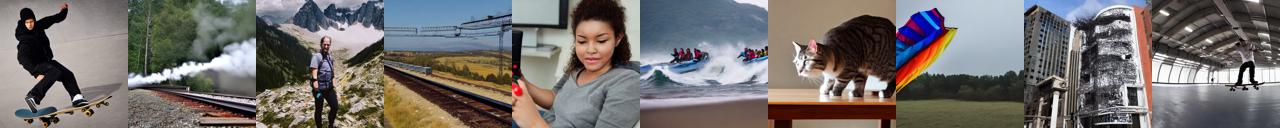

In [2]:
pipe = m2.load_pipeline()      # SD 1.5, float16, safety checker on
smoke = m2.smoke_check(pipe)
assert smoke["noise_ok"] and smoke["timesteps_ok"], "Smoke check failed: check the diffusers version (0.42.1) before running anything else"

from PIL import Image
from pathlib import Path
thumbs = [Image.open(p).resize((128, 128)) for p in sorted(Path("m2_smoke").glob("*.png"))]
sheet = Image.new("RGB", (128 * len(thumbs), 128))
for i, t in enumerate(thumbs):
    sheet.paste(t, (128 * i, 0))
sheet

## 3. Guidance sweep: 5 values × 500 dev captions (seed_id 0)

Guidance 7.5 runs first because it is the anchor: its first 200 images are also the 30-step point of the step sweep. Then come the two ends (3 and 12), then the middle values, so that if time runs short the sweep already spans the full range. About 5 s per image on a T4: roughly 40 minutes per value.

In [3]:
GUIDANCE = (7.5, 3, 12, 5, 10)
log = m2.RunLog(DRIVE, owner="Tanmayi", axis="guidance")

for g in GUIDANCE:
    m2.run_config(pipe, m2.GenConfig(guidance=g), "dev_500", log)

ddim-leading-s30-g7.5 on dev_500: 50/500 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: 100/500 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: 150/500 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: 200/500 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: 250/500 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: 300/500 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: 350/500 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: 400/500 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: 450/500 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: 500/500 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: done, 600 images, 4 flagged, 5.415 s/image
ddim-leading-s30-g3 on dev_500: 50/500 prompts, resumed
ddim-leading-s30-g3 on dev_500: 100/500 prompts, resumed
ddim-leading-s30-g3 on dev_500: 150/500 prompts, resumed
ddim-leading-s30-g3 on dev_500: 200/500 prompts, resumed
ddim-leading-s30-g3 on dev_500: 250/500 prompts, resumed
ddim-leading-s30-g3 on dev_500: 300/500 prompts, r

## 4. Diversity pairs: the first 100 dev captions again with seed_id 1

The same caption, the same setting, a different starting noise. Comparing the seed_id 0 and seed_id 1 pictures measures how much the output varies, which classifier-free guidance is known to reduce. About 40 minutes in total.

In [4]:
for g in GUIDANCE:
    m2.run_config(pipe, m2.GenConfig(guidance=g), "dev_500", log, seed_ids=(1,), first=100)

ddim-leading-s30-g7.5 on dev_500: 50/100 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: 100/100 prompts, resumed
ddim-leading-s30-g7.5 on dev_500: done, 600 images, 4 flagged, 5.415 s/image
ddim-leading-s30-g3 on dev_500: 50/100 prompts, resumed
ddim-leading-s30-g3 on dev_500: 100/100 prompts, resumed
ddim-leading-s30-g3 on dev_500: done, 600 images, 2 flagged, 5.433 s/image
ddim-leading-s30-g12 on dev_500: 50/100 prompts, resumed
ddim-leading-s30-g12 on dev_500: 100/100 prompts, resumed
ddim-leading-s30-g12 on dev_500: done, 600 images, 5 flagged, 5.423 s/image
ddim-leading-s30-g5 on dev_500: 50/100 prompts, resumed
ddim-leading-s30-g5 on dev_500: 100/100 prompts, resumed
ddim-leading-s30-g5 on dev_500: done, 600 images, 4 flagged, 5.431 s/image
ddim-leading-s30-g10 on dev_500: 50/100 prompts, resumed
ddim-leading-s30-g10 on dev_500: 100/100 prompts, resumed
ddim-leading-s30-g10 on dev_500: done, 600 images, 3 flagged, 5.425 s/image


## 5. Step sweep: 10, 20 and 50 steps on the first 200 dev captions

The 30-step point is the guidance-7.5 run above (the same setting, the same captions, the same noise), so it is not painted again. About 45 minutes on a T4.

*If Santhosh runs this sweep on his laptop instead, skip this cell. He sends his `images.csv` and `images/` folder, which go into `MyDrive/m2/steps_from_santhosh/`, and the scoring notebook reads them from there.*

In [5]:
steps_log = m2.RunLog(DRIVE, owner="Tanmayi", axis="steps")
for n in (10, 20, 50):
    m2.run_config(pipe, m2.GenConfig(steps=n), "dev_500", steps_log, first=200)

ddim-leading-s10-g7.5 on dev_500: 50/200 prompts, resumed
ddim-leading-s10-g7.5 on dev_500: 100/200 prompts, resumed
ddim-leading-s10-g7.5 on dev_500: 150/200 prompts, resumed
ddim-leading-s10-g7.5 on dev_500: 200/200 prompts, resumed
ddim-leading-s10-g7.5 on dev_500: done, 200 images, 2 flagged, 1.889 s/image
ddim-leading-s20-g7.5 on dev_500: 50/200 prompts, resumed
ddim-leading-s20-g7.5 on dev_500: 100/200 prompts, resumed
ddim-leading-s20-g7.5 on dev_500: 150/200 prompts, resumed
ddim-leading-s20-g7.5 on dev_500: 200/200 prompts, resumed
ddim-leading-s20-g7.5 on dev_500: done, 200 images, 0 flagged, 3.515 s/image
ddim-leading-s50-g7.5 on dev_500: 50/200 prompts, resumed
ddim-leading-s50-g7.5 on dev_500: 100/200 prompts, resumed
ddim-leading-s50-g7.5 on dev_500: 150/200 prompts, resumed
ddim-leading-s50-g7.5 on dev_500: 200/200 prompts, resumed
ddim-leading-s50-g7.5 on dev_500: done, 200 images, 0 flagged, 8.398 s/image


## 6. Correct the run log

`run_config` rewrites a setting's row in `runs.csv` each time it is called, so after the diversity pairs each guidance row would describe only the 100-caption seed_id 1 run. This cell rewrites each row to describe the whole run (its image count is taken from `images.csv` either way) and records that the 30-step point of the step sweep is the guidance-7.5 run.

In [6]:
import pandas as pd

for g in GUIDANCE:
    note = "seed_id 0 on all 500 dev captions; seed_id 1 on the first 100 (diversity pairs)"
    if g == 7.5:
        note += "; its first 200 seed_id 0 images are also the 30-step point of the step sweep"
    log.add_run(m2.GenConfig(guidance=g), "dev_500", n_prompts=500, seed_ids=(0, 1), notes=note)

runs = pd.read_csv(f"{DRIVE}/runs.csv")
runs[["config_id", "axis", "split", "n_prompts", "seed_ids", "n_images", "n_flagged", "sec_per_image", "gpu", "diffusers_version", "notes"]]

,config_id,axis,split,n_prompts,seed_ids,n_images,n_flagged,sec_per_image,gpu,diffusers_version,notes
0,ddim-leading-s30-g7.5,final numbers (eval_500),eval_500,500,0,500,1,4.881,Tesla T4,0.42.1,"anchor, for comparison with the chosen setting"
1,ddim-leading-s10-g7.5,final numbers (eval_500),eval_500,500,0,500,2,1.802,Tesla T4,0.42.1,setting chosen on dev_500 (analysis/chosen.json)
2,ddim-leading-s10-g7.5,steps,dev_500,200,0,200,2,1.889,Tesla T4,0.42.1,NaN
3,ddim-leading-s20-g7.5,steps,dev_500,200,0,200,0,3.515,Tesla T4,0.42.1,NaN
4,ddim-leading-s50-g7.5,steps,dev_500,200,0,200,0,8.398,Tesla T4,0.42.1,NaN
5,ddim-leading-s30-g7.5,guidance,dev_500,500,0 1,600,4,5.415,Tesla T4,0.42.1,seed_id 0 on all 500 dev captions; seed_id 1 o...
6,ddim-leading-s30-g3,guidance,dev_500,500,0 1,600,2,5.433,Tesla T4,0.42.1,seed_id 0 on all 500 dev captions; seed_id 1 o...
7,ddim-leading-s30-g12,guidance,dev_500,500,0 1,600,5,5.423,Tesla T4,0.42.1,seed_id 0 on all 500 dev captions; seed_id 1 o...
8,ddim-leading-s30-g5,guidance,dev_500,500,0 1,600,4,5.431,Tesla T4,0.42.1,seed_id 0 on all 500 dev captions; seed_id 1 o...
9,ddim-leading-s30-g10,guidance,dev_500,500,0 1,600,3,5.425,Tesla T4,0.42.1,seed_id 0 on all 500 dev captions; seed_id 1 o...


## 7. Final numbers on eval_500, three seeds (run only after the analysis notebook has chosen a setting)

The analysis notebook applies the selection rules to the `dev_500` scores and writes `analysis/chosen.json`. This cell paints the chosen setting and the anchor on the 500 `eval_500` captions, the test captions that no choice has looked at, with seed_ids 0, 1 and 2 (1,500 images per setting). If the chosen setting is the anchor, only the anchor is painted. Images already on Drive are kept, so a rerun adds only what is missing: on a T4, about 80 minutes per 1,000 images at 30 steps and 30 minutes at 10 steps.

In [7]:
import json

chosen = json.load(open(f"{DRIVE}/analysis/chosen.json"))
final = m2.GenConfig(steps=chosen["steps"], guidance=chosen["guidance"])
print("chosen on dev_500:", final.config_id, "| anchor:", m2.ANCHOR.config_id)

SEEDS = (0, 1, 2)
eval_log = m2.RunLog(DRIVE, owner="Tanmayi", axis="final numbers (eval_500)")
finals = [(m2.ANCHOR, "anchor, for comparison with the chosen setting")]
if final != m2.ANCHOR:
    finals.append((final, "setting chosen on dev_500 (analysis/chosen.json)"))
for cfg, note in finals:
    m2.run_config(pipe, cfg, "eval_500", eval_log, seed_ids=SEEDS, notes=note)
    eval_log.add_run(cfg, "eval_500", n_prompts=500, seed_ids=SEEDS, notes=note + "; seed_ids 0, 1, 2 on all 500 captions")

chosen on dev_500: ddim-leading-s10-g7.5 | anchor: ddim-leading-s30-g7.5
ddim-leading-s30-g7.5 on eval_500: 50/500 prompts, 4.52 s/image
ddim-leading-s30-g7.5 on eval_500: 100/500 prompts, 4.53 s/image
ddim-leading-s30-g7.5 on eval_500: 150/500 prompts, 4.53 s/image
ddim-leading-s30-g7.5 on eval_500: 200/500 prompts, 4.54 s/image
ddim-leading-s30-g7.5 on eval_500: 250/500 prompts, 4.54 s/image
ddim-leading-s30-g7.5 on eval_500: 300/500 prompts, 4.55 s/image
ddim-leading-s30-g7.5 on eval_500: 350/500 prompts, 4.55 s/image
ddim-leading-s30-g7.5 on eval_500: 400/500 prompts, 4.55 s/image
ddim-leading-s30-g7.5 on eval_500: 450/500 prompts, 4.55 s/image
ddim-leading-s30-g7.5 on eval_500: 500/500 prompts, 4.54 s/image
ddim-leading-s30-g7.5 on eval_500: done, 1500 images, 1 flagged, 4.656 s/image
ddim-leading-s10-g7.5 on eval_500: 50/500 prompts, 1.66 s/image
ddim-leading-s10-g7.5 on eval_500: 100/500 prompts, 1.65 s/image
ddim-leading-s10-g7.5 on eval_500: 150/500 prompts, 1.65 s/image


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


ddim-leading-s10-g7.5 on eval_500: 200/500 prompts, 1.65 s/image


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


ddim-leading-s10-g7.5 on eval_500: 250/500 prompts, 1.65 s/image
ddim-leading-s10-g7.5 on eval_500: 300/500 prompts, 1.65 s/image


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


ddim-leading-s10-g7.5 on eval_500: 350/500 prompts, 1.65 s/image
ddim-leading-s10-g7.5 on eval_500: 400/500 prompts, 1.65 s/image


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


ddim-leading-s10-g7.5 on eval_500: 450/500 prompts, 1.65 s/image
ddim-leading-s10-g7.5 on eval_500: 500/500 prompts, 1.66 s/image
ddim-leading-s10-g7.5 on eval_500: done, 1500 images, 6 flagged, 1.705 s/image


## 8. What was painted

The images stay on Drive. `runs.csv` and `images.csv` go into the group repository's `milestone-2/expN/` folder (the analysis notebook copies them into `MyDrive/m2/export/` together with the result tables).

In [9]:
imgs = pd.read_csv(f"{DRIVE}/images.csv")
imgs.groupby(["split", "config_id", "seed_id"]).agg(images=("file", "size"), flagged=("flagged", "sum"),
                                                     sec_per_image=("seconds", "mean")).round(2)

images  flagged  sec_per_image
split    config_id             seed_id                                
dev_500  ddim-leading-s10-g7.5 0           200        2           1.89
         ddim-leading-s20-g7.5 0           200        0           3.52
         ddim-leading-s30-g10  0           500        1           5.48
                               1           100        2           5.15
         ddim-leading-s30-g12  0           500        3           5.48
                               1           100        2           5.14
         ddim-leading-s30-g3   0           500        1           5.49
                               1           100        1           5.14
         ddim-leading-s30-g5   0           500        2           5.49
                               1           100        2           5.15
         ddim-leading-s30-g7.5 0           500        2           5.48
                               1           100        2           5.10
         ddim-leading-s50-g7.5 0           200        0           8.40
eval_500 ddim-leading-s10-g7.5 0           500        2           1.80
                               1           500        2           1.66
                               2           500        2           1.66
         ddim-leading-s30-g7.5 0           500        1           4.88
                               1           500        0           4.54
                               2           500        0           4.54